<a href="https://colab.research.google.com/github/Azam223905/Data-Analytics-Internship/blob/main/Task2_Titanic_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
df.shape

(891, 15)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [5]:
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


In [6]:
# umar ki khali jagah median se bharna
df["age"] = df["age"].fillna(df["age"].median())

# bandargah ki khali jagah sab se common value se bharna
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
df["embark_town"] = df["embark_town"].fillna(df["embark_town"].mode()[0])

# deck column hata dena
df = df.drop(columns=["deck"])

In [7]:
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0
class,0
who,0


In [8]:
df.duplicated().sum()

np.int64(116)

In [9]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [10]:
# sab musafiron mein se kitne bache
df["survived"].mean()

np.float64(0.3838383838383838)

In [11]:
# mard aur aurat ke hisaab se
df.groupby("sex")["survived"].mean()

,survived
sex,
female,0.742038
male,0.188908


In [12]:
# class ke hisaab se (1 = sab se mehngi, 3 = sab se sasti)
df.groupby("pclass")["survived"].mean()

,survived
pclass,
1,0.629630
2,0.472826
3,0.242363


In [13]:
# gender aur class dono ko mila kar
df.groupby(["sex", "pclass"])["survived"].mean()

sex     pclass
female  1         0.968085
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: survived, dtype: float64

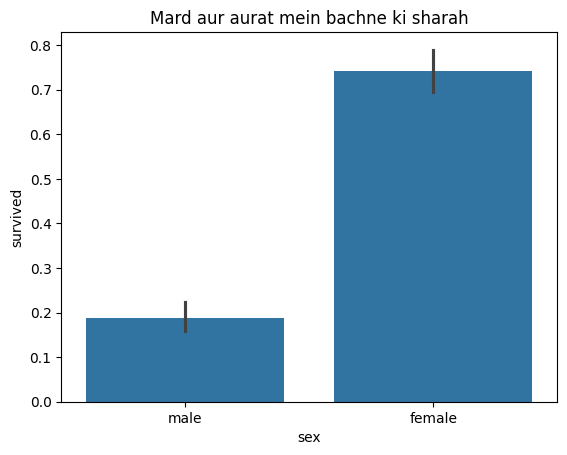

In [14]:
sns.barplot(x="sex", y="survived", data=df)
plt.title("Mard aur aurat mein bachne ki sharah")
plt.show()

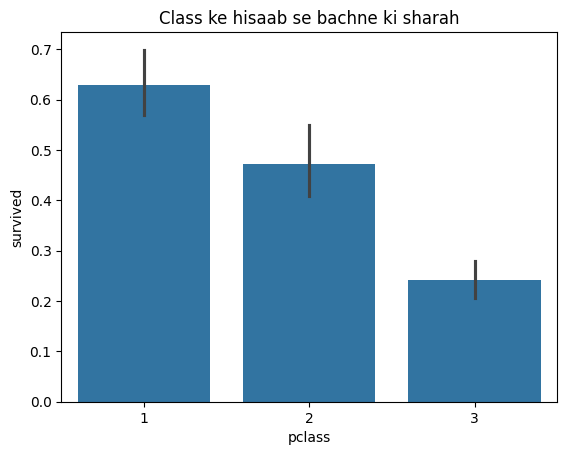

In [15]:
sns.barplot(x="pclass", y="survived", data=df)
plt.title("Class ke hisaab se bachne ki sharah")
plt.show()

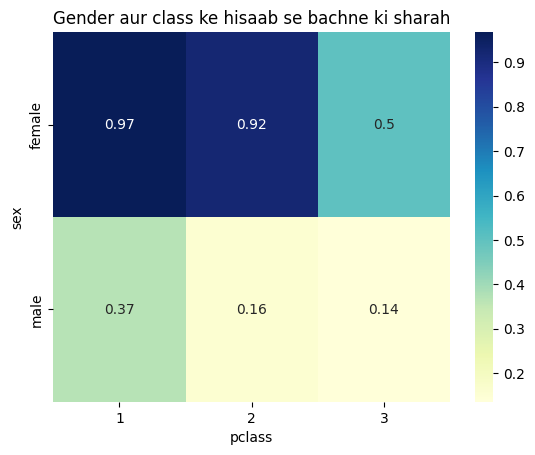

In [16]:
table = df.pivot_table(values="survived", index="sex", columns="pclass", aggfunc="mean")

sns.heatmap(table, annot=True, cmap="YlGnBu")
plt.title("Gender aur class ke hisaab se bachne ki sharah")
plt.show()

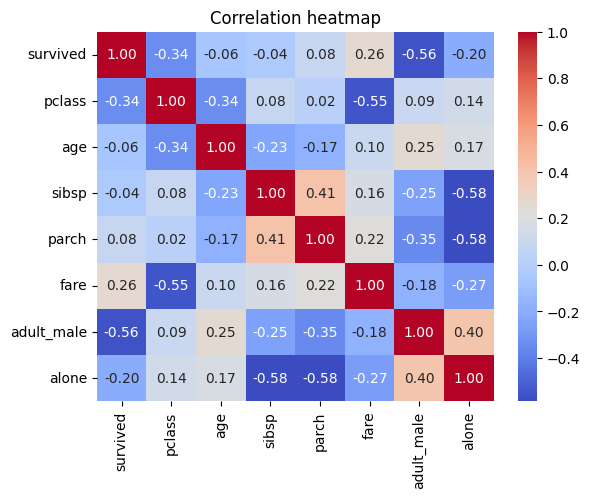

In [17]:
corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

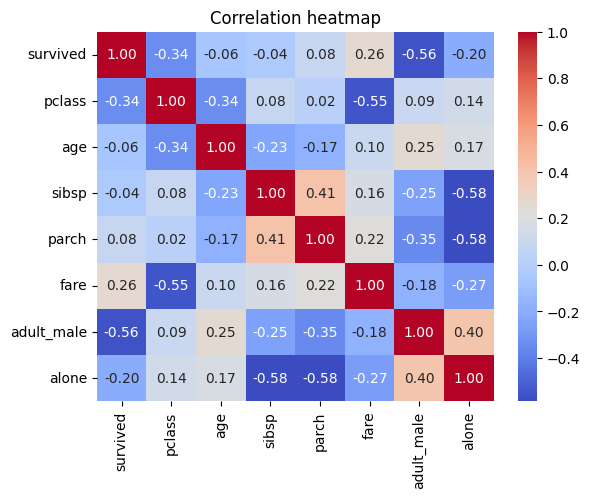

In [18]:
corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

Total 38% people alive.
Women were much more likely to survive than men.
People in the first class have more children than those in the third class.
Fill in the blanks of 177 items with the median, and remove the deck column because it is 77% empty.

